# 1. Exploratory Data Analysis (EDA)

## 1.1 Objective

This section explores the retail sales dataset to identify sales patterns, trends, and differences across product families. The analysis will help determine suitable preprocessing strategies and provide insights for monthly sales forecasting.

## 1.2 Analysis Scope

The exploratory analysis covers:
- Overall sales trends over time.
- Monthly sales patterns.
- Sales distribution across product families.
- Zero-sales observations.
- Potential seasonal patterns and unusual sales values.

The analysis will use the original daily dataset before aggregation and preprocessing.

In [71]:
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [72]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = '/content/drive/MyDrive/retail-sales-forecasting/data/raw/train.csv'

df = pd.read_csv(file_path)

df['date'] = pd.to_datetime(df['date'])

print('Dataset shape:', df.shape)
print('Date range:', df['date'].min(), 'to', df['date'].max())
print('Number of product families:', df['family'].nunique())

Dataset shape: (3000888, 6)
Date range: 2013-01-01 00:00:00 to 2017-08-15 00:00:00
Number of product families: 33


# 2. Sales Trend Analysis

## 2.1 Daily Total Sales Trend

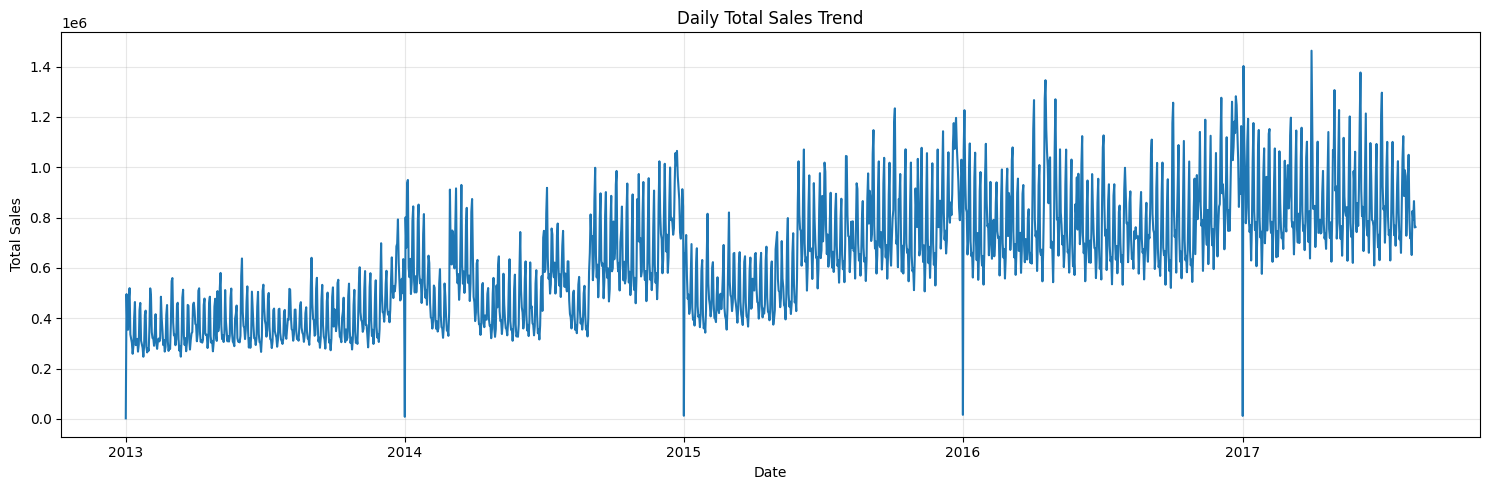

In [73]:
daily_sales = (
    df.groupby('date', as_index=False)['sales']
    .sum()
)

plt.figure(figsize=(15, 5))
plt.plot(daily_sales['date'], daily_sales['sales'])
plt.title('Daily Total Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [74]:
print('Daily sales statistics:')
display(daily_sales['sales'].describe().to_frame(name='Daily Sales'))

Daily sales statistics:


,Daily Sales
count,1.684000e+03
mean,6.375564e+05
std,2.344102e+05
min,2.511619e+03
25%,4.427115e+05
50%,6.321889e+05
75%,7.859455e+05
max,1.463084e+06


**Interpretation**

The daily sales trend shows an overall increase in total sales from 2013 to 2017. Daily sales were generally lower in the earlier period and tended to be higher in 2016 and 2017.

The chart also shows frequent fluctuations in daily sales, indicating that sales vary considerably over time. Several sharp drops appear around the beginning of certain years, which may be related to specific calendar dates or operating patterns and require further investigation.

Daily sales range from approximately 2,512 to 1,463,084 units, with an average of approximately 637,556 units per day.

Overall, the analysis suggests an increasing sales trend with substantial daily fluctuations. Further analysis using monthly sales data will help identify broader trends and potential seasonal patterns more clearly.

## 2.2 Monthly Total Sales Trend

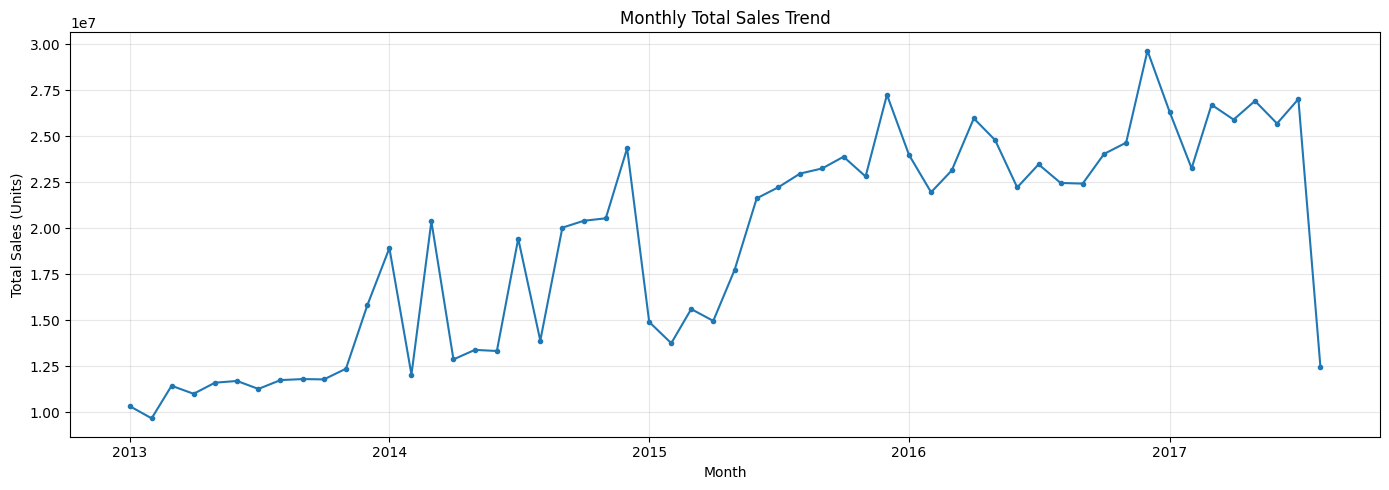

In [75]:
monthly_sales = (
    df.set_index('date')['sales']
    .resample('MS')
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_sales['date'],
    monthly_sales['sales'],
    marker='o',
    markersize=3
)

plt.title('Monthly Total Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (Units)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [76]:
print('Monthly sales statistics:')
display(monthly_sales['sales'].describe().to_frame(name='Monthly Sales'))

print('Number of months:', len(monthly_sales))

Monthly sales statistics:


,Monthly Sales
count,5.600000e+01
mean,1.917223e+07
std,5.806956e+06
min,9.658960e+06
25%,1.320528e+07
50%,2.046387e+07
75%,2.390315e+07
max,2.964029e+07


Number of months: 56


**Interpretation**

The monthly total sales trend shows an overall increase from 2013 to 2017. Monthly sales were approximately 10–12 million units in early 2013, while many months in 2016 and early 2017 recorded sales of approximately 22–27 million units.

Despite the overall upward trend, sales fluctuated considerably between months. These fluctuations indicate that sales did not increase consistently throughout the observation period, although their underlying causes require further investigation.

The final observation, August 2017, shows a sharp decline compared with previous months. However, the dataset only covers August 1–15, 2017, meaning that the monthly total is incomplete and should not be directly compared with totals from full months.

Overall, the analysis suggests an increasing long-term sales trend accompanied by substantial monthly fluctuations. Further analysis at the product family level is needed to understand differences in sales patterns and support the forecasting process.

# 3. Monthly Seasonality Analysis

## 3.1 Objective and Method

This section examines whether sales follow a recurring pattern across calendar months. The analysis aims to identify months with relatively high or low sales and investigate potential seasonal patterns in the dataset.

Daily sales records will be grouped by calendar month, from January to December, across the available years. The average daily sales for each calendar month will then be calculated and visualized using a bar chart.

Average daily sales are used instead of total monthly sales to make the comparison less affected by differences in the number of days in each month and the incomplete final month of August 2017.

The analysis will address the following questions:

- Which calendar months have the highest and lowest average daily sales?
- Does December tend to have higher average daily sales than other months?
- Do the results suggest a recurring seasonal pattern?

The findings will help determine whether seasonality should be considered in the subsequent forecasting process. However, observed patterns alone cannot establish the causes of seasonal changes.

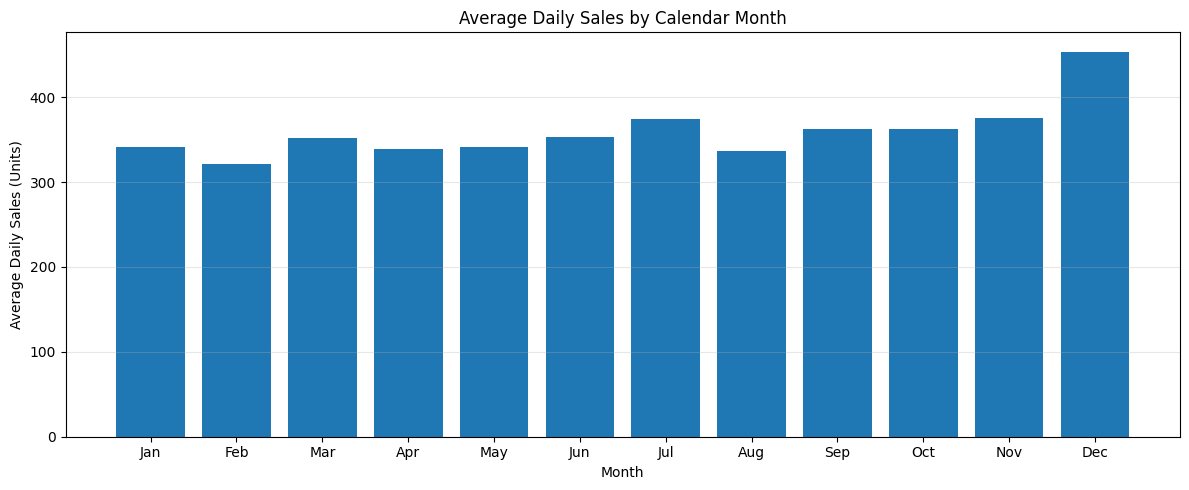

In [77]:
monthly_seasonality = (
    df.assign(month=df['date'].dt.month)
    .groupby('month', as_index=False)['sales']
    .mean()
)

month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_seasonality['month_name'] = monthly_seasonality['month'].map(
    lambda month: month_names[month - 1]
)

plt.figure(figsize=(12, 5))
plt.bar(
    monthly_seasonality['month_name'],
    monthly_seasonality['sales']
)

plt.title('Average Daily Sales by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales (Units)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [78]:
display(
    monthly_seasonality[['month_name', 'sales']]
    .rename(columns={
        'month_name': 'Month',
        'sales': 'Average Daily Sales'
    })
    .round(2)
)

,Month,Average Daily Sales
0,Jan,341.92
1,Feb,320.93
2,Mar,352.01
3,Apr,339.20
4,May,341.77
5,Jun,353.60
6,Jul,374.22
7,Aug,336.99
8,Sep,362.30
9,Oct,362.41


## 3.2 Yearly Consistency of Monthly Sales Patterns

### Objective

This analysis examines whether the monthly sales patterns observed in the previous section are consistent across different years. In particular, it compares December and February sales to evaluate whether December tends to have higher average daily sales and February tends to have lower average daily sales.

### Method

Daily sales will be grouped by year and calendar month. The average daily sales for each month will be calculated separately for each year and visualized in a line chart.

This approach allows monthly patterns to be compared across years rather than relying only on an overall average.

The analysis will focus on the following questions:

- Does December consistently show relatively high average daily sales?
- Does February consistently show relatively low average daily sales?
- Are there years in which the observed pattern differs?

The results will help assess the consistency of the observed monthly patterns. They will not, by themselves, establish the causes of seasonal changes.

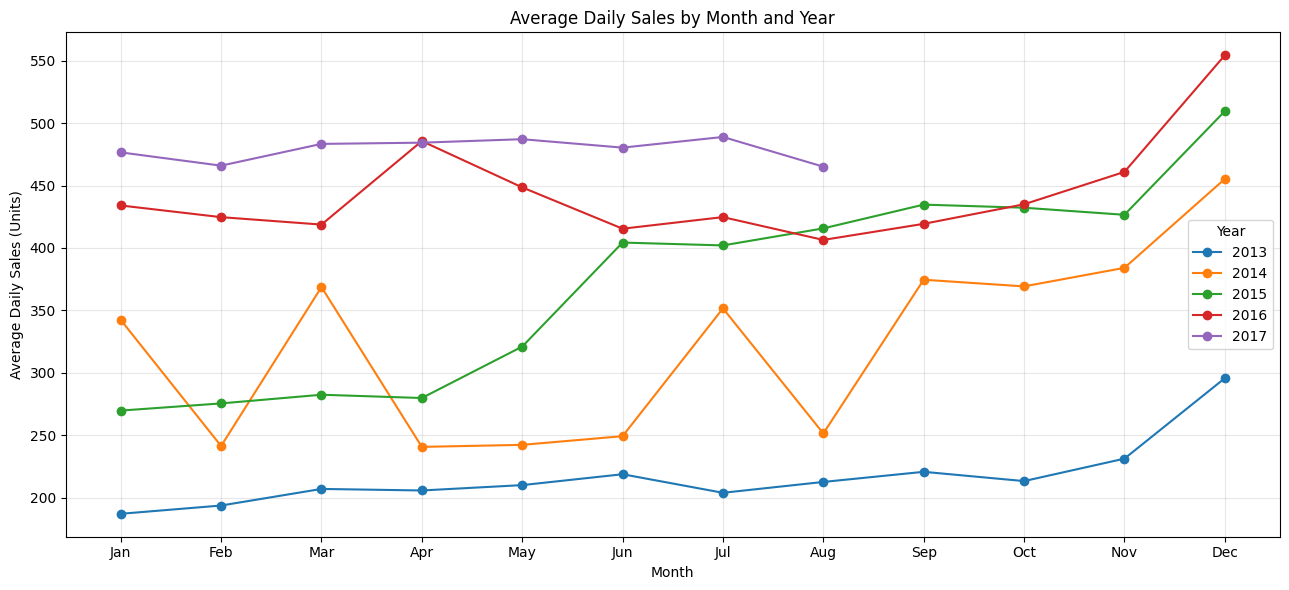

month,February,December,December - February
year,,,
2013,193.58,295.61,102.02
2014,241.27,455.30,214.03
2015,275.42,509.61,234.19
2016,424.70,554.44,129.74
2017,465.97,NaN,NaN


In [79]:
yearly_monthly_sales = (
    df.assign(
        year=df['date'].dt.year,
        month=df['date'].dt.month
    )
    .groupby(['year', 'month'], as_index=False)['sales']
    .mean()
)


plt.figure(figsize=(13, 6))

for year in sorted(yearly_monthly_sales['year'].unique()):
    yearly_data = yearly_monthly_sales[
        yearly_monthly_sales['year'] == year
    ]

    plt.plot(
        yearly_data['month'],
        yearly_data['sales'],
        marker='o',
        label=str(year)
    )

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.title('Average Daily Sales by Month and Year')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales (Units)')
plt.legend(title='Year')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Compare December and February by year
comparison = yearly_monthly_sales[
    yearly_monthly_sales['month'].isin([2, 12])
].pivot(
    index='year',
    columns='month',
    values='sales'
).rename(columns={
    2: 'February',
    12: 'December'
})

comparison['December - February'] = (
    comparison['December'] - comparison['February']
)

display(comparison.round(2))

**Interpretation**

The year-by-year analysis shows that average daily sales in December were higher than in February for every year with complete data for both months, from 2013 to 2016.

In 2013, average daily sales increased from 193.58 units in February to 295.61 units in December. The same pattern appeared in subsequent years. In 2016, average daily sales reached 554.44 units in December, compared with 424.70 units in February.

These findings suggest a recurring pattern of higher daily sales in December and lower daily sales in February. This pattern is consistent with the possibility that year-end shopping activities and seasonal events influence sales. However, the analysis does not establish the causes of these differences.

The 2017 comparison is unavailable because the dataset ends on August 15, 2017, and does not include December sales for that year.

Overall, the results provide evidence of a recurring monthly sales pattern that may be relevant to forecasting. Further analysis is needed to investigate other seasonal factors and differences across product families.

# 4. Sales Distribution by Product Family



## 4.1 Objective and Method

This section examines differences in sales across the 33 product families in the dataset. The objective is to identify product families with relatively high and low sales volumes and understand how sales are distributed across product categories.

Total sales will be aggregated by product family across all stores and dates. The results will be sorted and visualized using a bar chart to compare sales volumes between product families.

This analysis will help identify differences in sales scale across product families and provide context for the subsequent forecasting process.

The analysis will address the following questions:

- Which product families have the highest total sales?
- Which product families have the lowest total sales?
- How different are sales volumes across product families?

The analysis uses the available observations from January 2013 to August 15, 2017. Since the observation period is incomplete for 2017, the results represent total sales over the available dataset period rather than a complete set of calendar years.

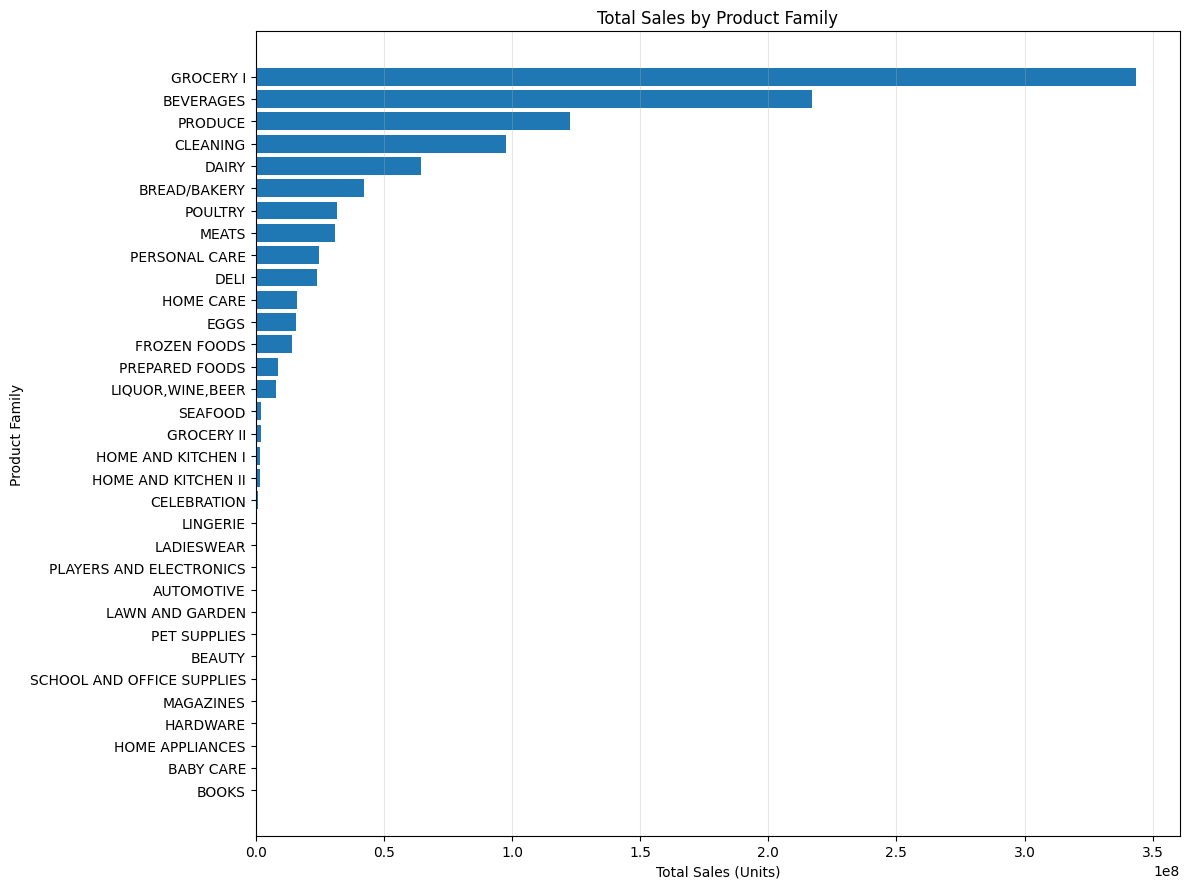

In [80]:
family_sales = (
    df.groupby('family', as_index=False)['sales']
    .sum()
    .sort_values('sales', ascending=False)
)

plt.figure(figsize=(12, 9))
plt.barh(
    family_sales['family'][::-1],
    family_sales['sales'][::-1]
)

plt.title('Total Sales by Product Family')
plt.xlabel('Total Sales (Units)')
plt.ylabel('Product Family')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [81]:
print('Top 10 Product Families by Total Sales')
display(family_sales.head(10).reset_index(drop=True))

Top 10 Product Families by Total Sales


,family,sales
0,GROCERY I,3.434627e+08
1,BEVERAGES,2.169545e+08
2,PRODUCE,1.227047e+08
3,CLEANING,9.752129e+07
4,DAIRY,6.448771e+07
5,BREAD/BAKERY,4.213395e+07
6,POULTRY,3.187600e+07
7,MEATS,3.108647e+07
8,PERSONAL CARE,2.459205e+07
9,DELI,2.411032e+07


In [82]:
print('Bottom 10 Product Families by Total Sales')
display(
    family_sales.tail(10)
    .sort_values('sales', ascending=True)
    .reset_index(drop=True)
)

Bottom 10 Product Families by Total Sales


,family,sales
0,BOOKS,6438.0
1,BABY CARE,10051.0
2,HOME APPLIANCES,41601.0
3,HARDWARE,103470.0
4,MAGAZINES,266359.0
5,SCHOOL AND OFFICE SUPPLIES,269316.0
6,BEAUTY,337893.0
7,PET SUPPLIES,356584.0
8,LAWN AND GARDEN,548842.0
9,AUTOMOTIVE,554822.0


**Interpretation**

The sales distribution analysis reveals substantial differences in total sales across the 33 product families.

GROCERY I recorded the highest total sales, with approximately 343.46 million units, followed by BEVERAGES with approximately 216.95 million units and PRODUCE with approximately 122.70 million units. These product families contributed substantially larger sales volumes than most other categories.

In contrast, BOOKS recorded the lowest total sales at 6,438 units, followed by BABY CARE at 10,051 units. Several other product families also recorded relatively low total sales over the observation period.

These findings indicate that sales volumes vary considerably across product families. However, total sales alone do not reveal whether a product family consistently has low sales each month or experiences occasional increases and decreases.

Further analysis of monthly sales patterns by product family is needed to understand these differences and support the development and evaluation of forecasting models.

## 4.2 Monthly Sales Patterns of Top Product Families

### Objective

This analysis examines monthly sales trends for the five product families with the highest total sales. The objective is to determine whether high-volume product families follow similar sales patterns or exhibit different trends and fluctuations over time.

### Method

Daily sales will be aggregated into monthly totals for each product family across all stores. The five product families with the highest total sales will then be visualized in a line chart.

The results will help illustrate differences in monthly sales behavior among major product families and provide additional context for the forecasting task.

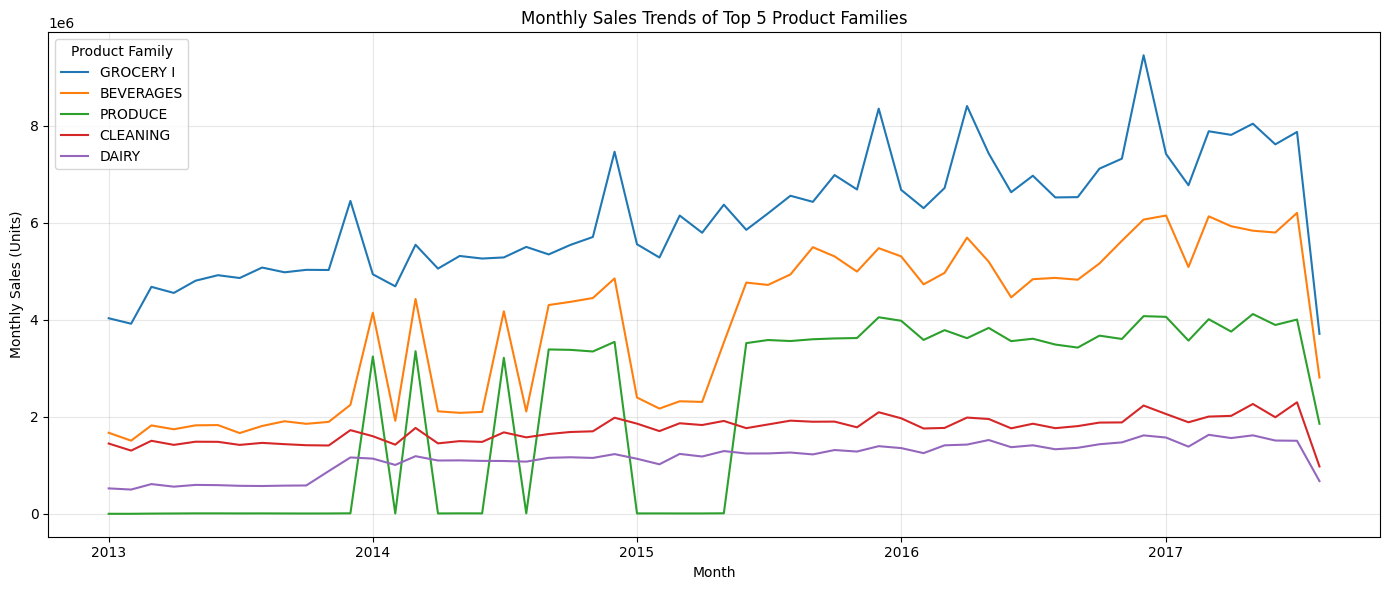

In [83]:
top_families = family_sales.head(5)['family'].tolist()

monthly_family_sales = (
    df.assign(month=df['date'].dt.to_period('M'))
    .groupby(['month', 'family'], as_index=False)['sales']
    .sum()
)

monthly_family_sales['date'] = (
    monthly_family_sales['month'].dt.to_timestamp()
)


plt.figure(figsize=(14, 6))

for family in top_families:
    family_data = monthly_family_sales[
        monthly_family_sales['family'] == family
    ]

    plt.plot(
        family_data['date'],
        family_data['sales'],
        label=family
    )

plt.title('Monthly Sales Trends of Top 5 Product Families')
plt.xlabel('Month')
plt.ylabel('Monthly Sales (Units)')
plt.legend(title='Product Family')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
produce_monthly = monthly_family_sales[
    monthly_family_sales['family'] == 'PRODUCE'
].copy()

display(
    produce_monthly[['date', 'sales']]
    .head(20)
)

print('Number of months:', len(produce_monthly))
print('Months with zero sales:', (produce_monthly['sales'] == 0).sum())
print('Months with positive sales:', (produce_monthly['sales'] > 0).sum())

,date,sales
30,2013-01-01,0.000000e+00
63,2013-02-01,0.000000e+00
96,2013-03-01,4.037000e+03
129,2013-04-01,6.308000e+03
162,2013-05-01,8.836000e+03
195,2013-06-01,8.631000e+03
228,2013-07-01,7.463000e+03
261,2013-08-01,8.118000e+03
294,2013-09-01,6.821000e+03
327,2013-10-01,5.910000e+03


Number of months: 56
Months with zero sales: 2
Months with positive sales: 54


**Interpretation**

The monthly sales trends of the five highest-selling product families reveal differences in sales volume and patterns over time.

GROCERY I recorded the highest sales volume among the five categories and showed an overall increasing trend throughout the observation period. BEVERAGES also exhibited an upward trend, although its sales fluctuated considerably between months.

PRODUCE showed several months with zero sales and substantial increases in other periods. Further inspection confirmed that January and February 2013 had zero recorded sales for this product family. These observations should be considered carefully when interpreting its monthly sales pattern.

CLEANING and DAIRY recorded lower sales volumes than GROCERY I, BEVERAGES, and PRODUCE. Their monthly trends appeared relatively more stable, although fluctuations were still present.

The chart also shows changes occurring around similar periods for some product families. However, this visual pattern alone does not establish that all categories share the same seasonal behavior or that a particular event caused the observed changes.

The sharp decline at the end of the chart should also be interpreted cautiously because the dataset ends on August 15, 2017, making the final month's sales incomplete.

Overall, the analysis indicates that product families differ in sales scale and monthly behavior. These differences provide useful context for preparing the data and evaluating forecasting models across all 33 product families.

In [85]:
produce_daily_check = df.loc[
    (df['family'] == 'PRODUCE') &
    (df['date'].dt.strftime('%Y-%m').isin(['2014-01', '2014-03'])),
    ['date', 'store_nbr', 'sales']
].copy()

daily_produce_sales = (
    produce_daily_check
    .groupby('date', as_index=False)['sales']
    .sum()
)

print('Number of daily records:', len(daily_produce_sales))

print('\nDaily sales summary:')
display(daily_produce_sales['sales'].describe().to_frame(name='Daily Sales'))


Number of daily records: 62

Daily sales summary:


,Daily Sales
count,62.000000
mean,106386.497325
std,25535.939660
min,1198.343400
25%,89447.035025
50%,98606.619550
75%,127601.785300
max,150551.856020


In [86]:
print('\nHighest daily total sales:')
display(
    daily_produce_sales
    .sort_values('sales', ascending=False)
    .head(10)
)


Highest daily total sales:


,date,sales
4,2014-01-05,150551.85602
35,2014-03-05,147733.57457
46,2014-03-16,146244.85703
7,2014-01-08,144872.59137
39,2014-03-09,142854.80200
3,2014-01-04,139361.68380
60,2014-03-30,136004.84950
18,2014-01-19,135768.32800
11,2014-01-12,135340.60479
53,2014-03-23,134413.48100


# 5. Monthly Sales Patterns Across All Product Families



## 5.1 Objective and Method

This analysis examines monthly sales patterns across all 33 product families to identify differences in sales trends and fluctuations over time.

Monthly sales are aggregated by product family across all stores. A set of separate line charts is then used to visualize each product family's monthly sales. This approach makes it easier to observe individual patterns without overcrowding a single chart.

The analysis focuses on identifying increasing or decreasing trends, monthly fluctuations, and differences in sales behavior across product families. These findings will provide additional context for data preprocessing and forecasting model evaluation.

Each panel uses its own vertical scale to make patterns visible for both high-volume and low-volume product families. Therefore, the charts are intended to compare patterns rather than absolute sales volumes.

In [87]:
monthly_family_sales = (
    df.assign(month=df['date'].dt.to_period('M'))
    .groupby(['month', 'family'], as_index=False)['sales']
    .sum()
)

monthly_family_sales['date'] = (
    monthly_family_sales['month'].dt.to_timestamp()
)

display(monthly_family_sales.head())
print('Number of product families:', monthly_family_sales['family'].nunique())
print('Number of monthly records:', len(monthly_family_sales))

,month,family,sales,date
0,2013-01,AUTOMOTIVE,6557.0,2013-01-01
1,2013-01,BABY CARE,0.0,2013-01-01
2,2013-01,BEAUTY,4019.0,2013-01-01
3,2013-01,BEVERAGES,1670653.0,2013-01-01
4,2013-01,BOOKS,0.0,2013-01-01


Number of product families: 33
Number of monthly records: 1848


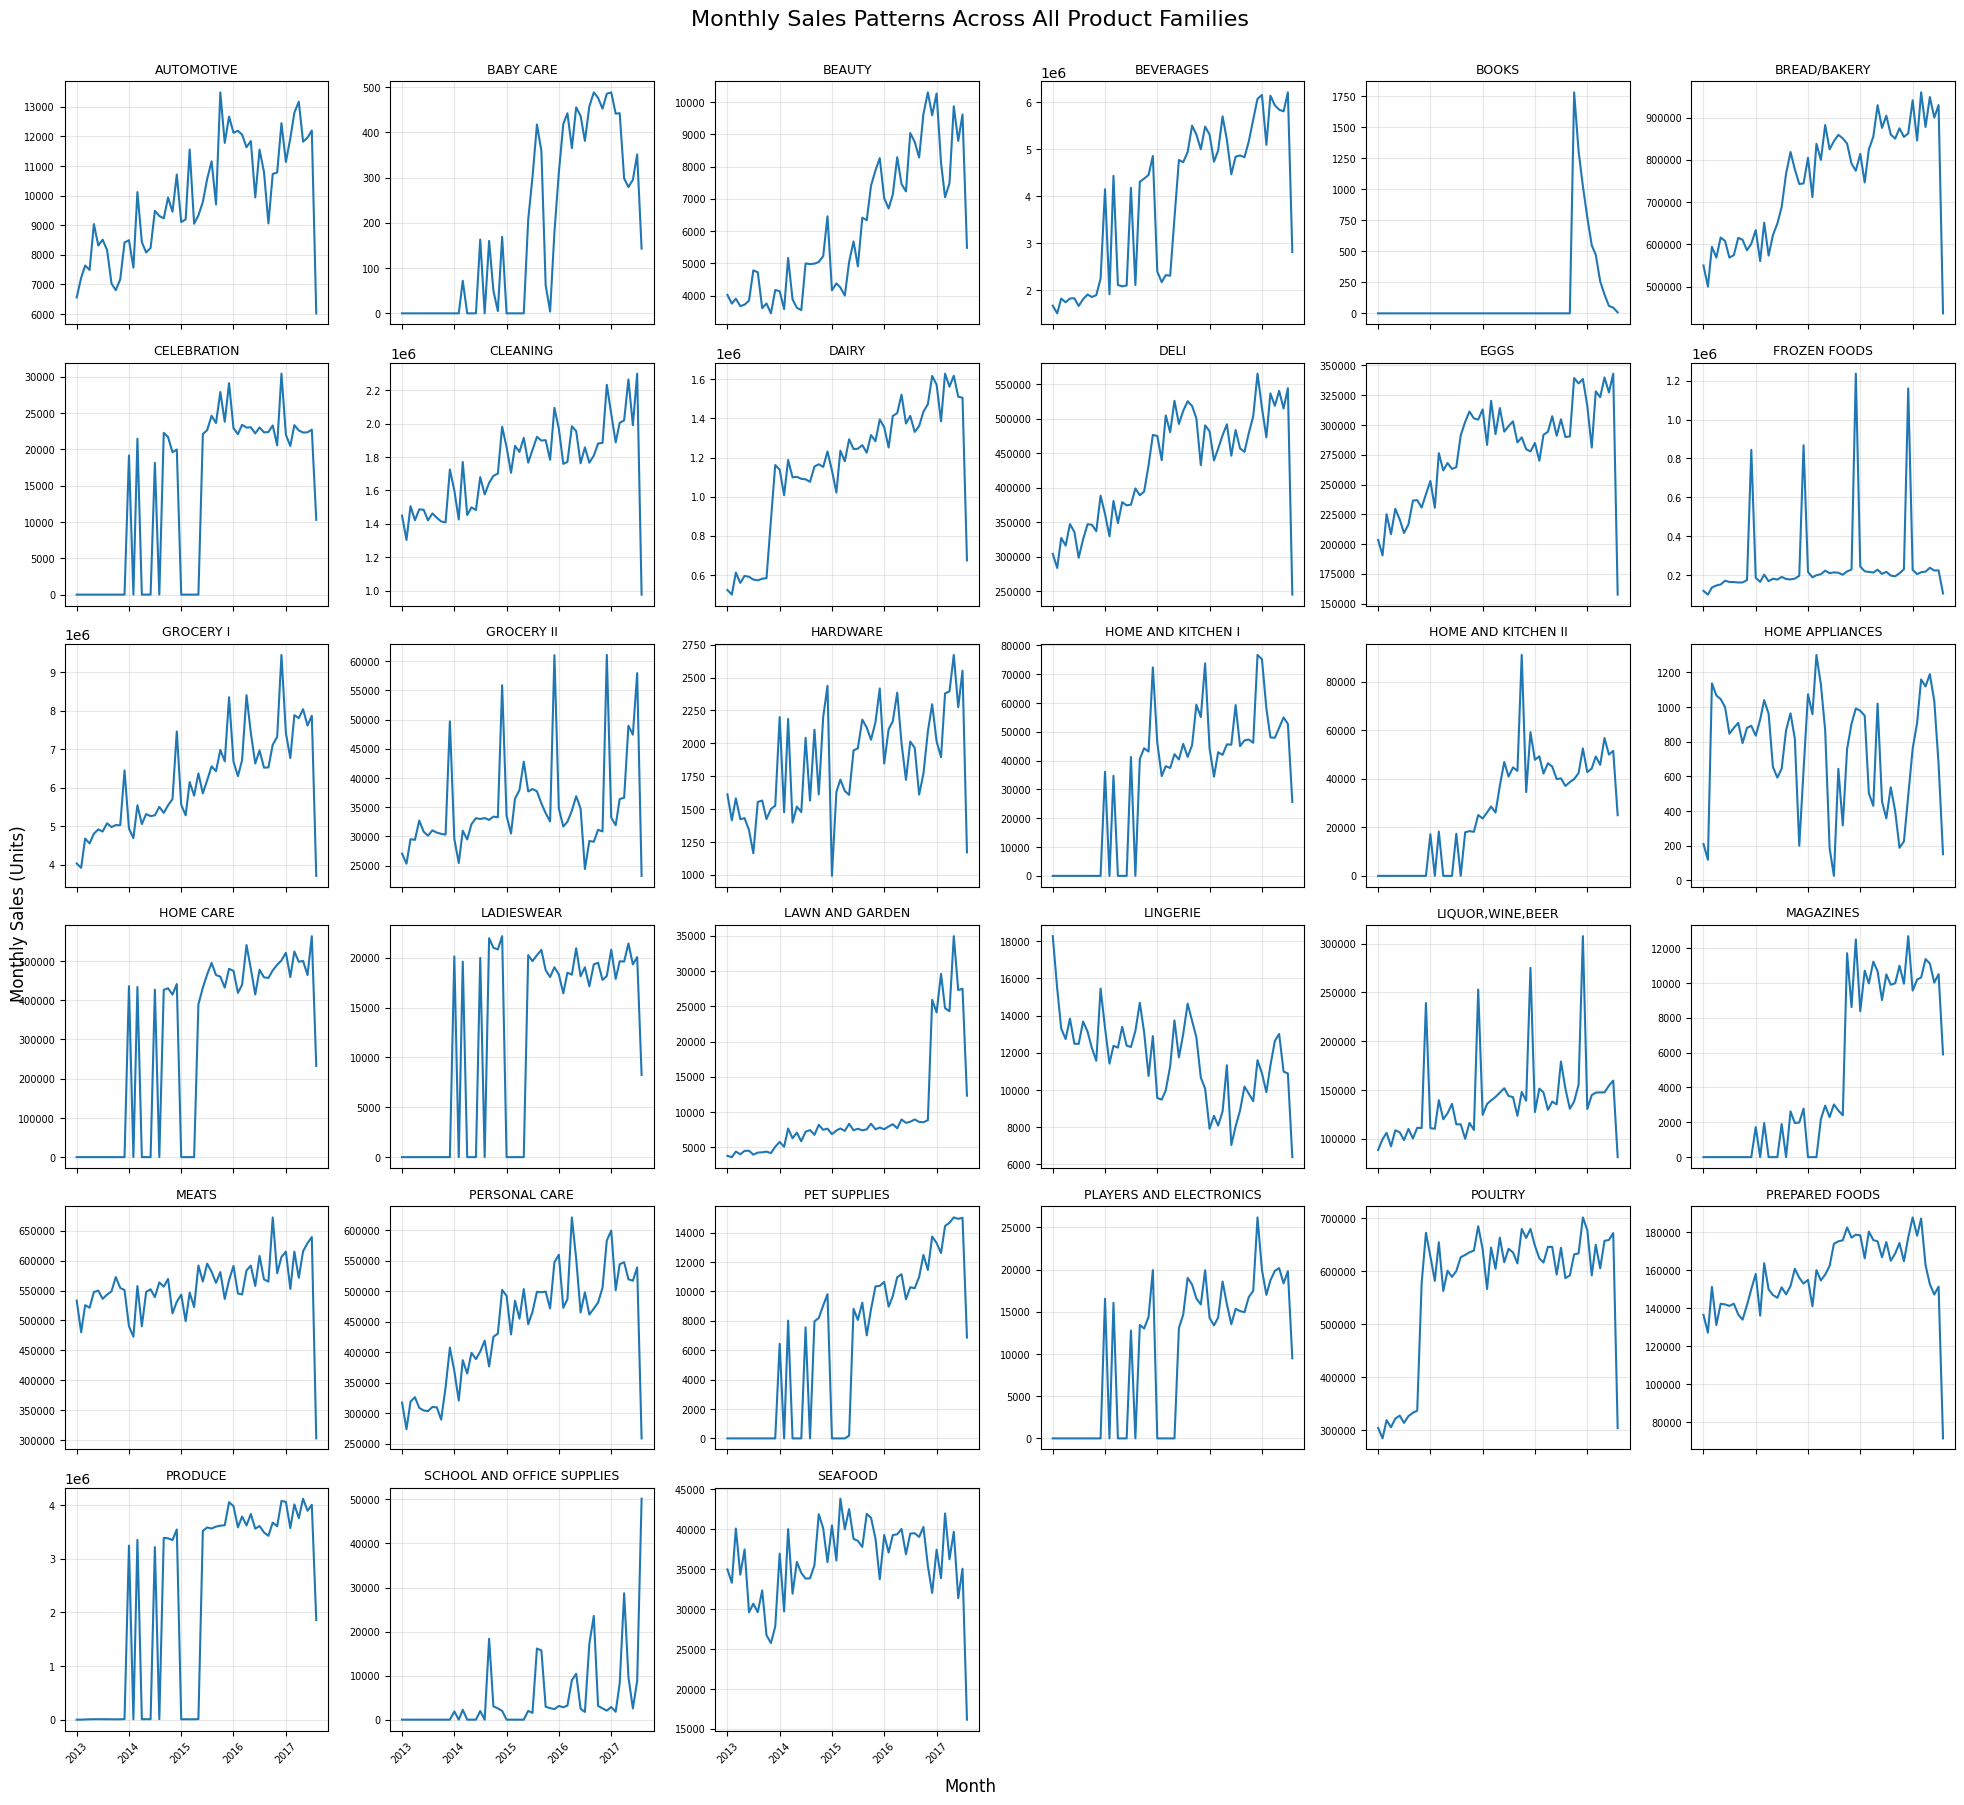

In [88]:
import matplotlib.pyplot as plt
import math

families = sorted(monthly_family_sales['family'].unique())

n_cols = 6
n_rows = math.ceil(len(families) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 3),
    sharex=True
)

axes = axes.flatten()

for i, family in enumerate(families):
    ax = axes[i]

    family_data = monthly_family_sales[
        monthly_family_sales['family'] == family
    ]

    ax.plot(
        family_data['date'],
        family_data['sales']
    )

    ax.set_title(family, fontsize=9)
    ax.tick_params(axis='x', labelrotation=45, labelsize=7)
    ax.tick_params(axis='y', labelsize=7)
    ax.grid(True, alpha=0.3)

for i in range(len(families), len(axes)):
    axes[i].set_visible(False)

fig.suptitle(
    'Monthly Sales Patterns Across All Product Families',
    fontsize=16,
    y=1.002
)

fig.supxlabel('Month')
fig.supylabel('Monthly Sales (Units)')

plt.tight_layout()
plt.show()

**Interpretation**

The monthly sales patterns vary considerably across product families. Several high-volume categories, such as GROCERY I and BEVERAGES, generally show increasing sales trends with noticeable fluctuations. Other categories, including MEATS, POULTRY, DELI, and SEAFOOD, exhibit comparatively more stable patterns.

Some product families, such as BOOKS, CELEBRATION, LADIESWEAR, and PLAYERS AND ELECTRONICS, contain periods of zero sales or sharp increases. These patterns require further investigation before determining whether they reflect actual demand behavior or data-related issues.

A sharp decline appears in many product families at the end of the observation period. This is likely influenced by August 2017 being an incomplete month, as the dataset ends on August 15, 2017.

These findings indicate that product families have different sales characteristics. Further data completeness checks are needed before finalizing preprocessing decisions and forecasting model development.

# 6. Monthly Data Completeness and Variation



## 6.1 Objective and Method

This analysis evaluates the completeness of monthly sales data and the variation in sales across product families. The completeness check aims to identify any missing monthly observations for each product family within the observation period.

Monthly completeness is important because missing periods may affect time-series analysis and forecasting. A month with no recorded observation must be distinguished from a month with recorded sales equal to zero.

The dataset ends on August 15, 2017, making August 2017 an incomplete month. This limitation has already been identified during the initial data understanding stage and will be considered when preparing data for forecasting.

## 6.2 Monthly Data Completeness Check

This step checks whether each product family has recorded sales data for every month within the observation period. The expected number of months is determined from the earliest and latest months in the dataset.

The number of observed months is then compared with the expected number of months for each product family. This helps identify product families with potentially missing monthly observations before proceeding to further analysis.

The results will be used to assess whether the monthly dataset has a consistent time structure for forecasting.

In [89]:
expected_months = pd.period_range(
    start=monthly_family_sales['month'].min(),
    end=monthly_family_sales['month'].max(),
    freq='M'
)

monthly_completeness = (
    monthly_family_sales
    .groupby('family')
    .agg(
        observed_months=('month', 'nunique'),
        total_monthly_sales=('sales', 'sum')
    )
    .reset_index()
)

# Calculate missing months
monthly_completeness['missing_months'] = (
    len(expected_months) - monthly_completeness['observed_months']
)

display(
    monthly_completeness
    .sort_values(
        ['missing_months', 'family'],
        ascending=[False, True]
    )
)

print('Expected months:', len(expected_months))
print('Product families:', monthly_completeness['family'].nunique())
print(
    'Families with missing months:',
    (monthly_completeness['missing_months'] > 0).sum()
)

,family,observed_months,total_monthly_sales,missing_months
0,AUTOMOTIVE,56,5.548220e+05,0
1,BABY CARE,56,1.005100e+04,0
2,BEAUTY,56,3.378930e+05,0
3,BEVERAGES,56,2.169545e+08,0
4,BOOKS,56,6.438000e+03,0
5,BREAD/BAKERY,56,4.213395e+07,0
6,CELEBRATION,56,7.611770e+05,0
7,CLEANING,56,9.752129e+07,0
8,DAIRY,56,6.448771e+07,0
9,DELI,56,2.411032e+07,0


Expected months: 56
Product families: 33
Families with missing months: 0


**Interpretation**

The completeness check shows that all 33 product families have recorded observations for all 56 months in the dataset. No missing monthly observations were identified, resulting in zero missing months across all product families.

This indicates that the aggregated monthly dataset has a consistent time structure for subsequent time-series analysis. However, the result only confirms the presence of monthly records and does not guarantee that every day within each month is complete. It also does not mean that all recorded months have positive sales.

The dataset can proceed to the next analysis stage, which examines the variation in monthly sales across product families.

## 6.3 Monthly Sales Variation

### Objective and Method

This analysis examines the variation in monthly sales across all product families to understand differences in sales stability and fluctuation.

For each product family, descriptive statistics are calculated, including the mean, standard deviation, minimum, maximum, and coefficient of variation (CV). The coefficient of variation measures the standard deviation relative to the mean, allowing sales variability to be compared across product families with different sales scales.

These statistics help identify product families with relatively stable sales and those with substantial fluctuations. The findings will provide additional context for selecting and evaluating forecasting models.

In [90]:
# Calculate monthly sales variation by product family
sales_variation = (
    monthly_family_sales
    .groupby('family')['sales']
    .agg(
        mean_sales='mean',
        std_sales='std',
        min_sales='min',
        max_sales='max'
    )
    .reset_index()
)

# Calculate coefficient of variation
sales_variation['cv'] = (
    sales_variation['std_sales'] / sales_variation['mean_sales']
)


display(
    sales_variation
    .sort_values('cv', ascending=False)
    .round(2)
)

,family,mean_sales,std_sales,min_sales,max_sales,cv
4,BOOKS,114.96,341.81,0.00,1783.00,2.97
31,SCHOOL AND OFFICE SUPPLIES,4809.21,8845.69,0.00,50169.00,1.84
1,BABY CARE,179.48,192.46,0.00,488.00,1.07
23,MAGAZINES,4756.41,4806.15,0.00,12692.00,1.01
11,FROZEN FOODS,251319.42,224393.73,98706.20,1236634.19,0.89
26,PET SUPPLIES,6367.57,5520.15,0.00,15027.00,0.87
27,PLAYERS AND ELECTRONICS,10046.57,8511.34,0.00,26175.00,0.85
6,CELEBRATION,13592.45,11317.73,0.00,30438.00,0.83
19,LADIESWEAR,11627.84,9611.98,0.00,22165.00,0.83
30,PRODUCE,2191155.08,1799328.68,0.00,4119032.74,0.82


**Interpretation**

The monthly sales variation analysis reveals substantial differences in sales behavior across product families. BOOKS has the highest coefficient of variation (CV) at 2.97, followed by SCHOOL AND OFFICE SUPPLIES at 1.84. These categories exhibit high relative variability compared with their average monthly sales. BABY CARE and MAGAZINES also show relatively high CV values.

In contrast, MEATS has the lowest CV at 0.09, followed by PREPARED FOODS at 0.12 and SEAFOOD at 0.14. These categories have comparatively lower variation relative to their average sales. However, lower CV values do not necessarily imply the absence of trends or seasonality.

High absolute variation does not always indicate high relative variation. For example, GROCERY I has a standard deviation of approximately 1.26 million units but a CV of 0.20, whereas BOOKS has a much smaller standard deviation but a CV of 2.97. This highlights the importance of considering both sales scale and relative variability when comparing product families.

The CV values provide descriptive insights into sales variability but do not identify its causes or directly measure forecasting difficulty. Trends, seasonal patterns, zero-sales months, and occasional spikes may all contribute to the observed variation. These findings will inform further data preparation and model evaluation without justifying automatic removal or modification of any product family.

# 7. EDA Summary


---


## 7.1 Key Findings

The exploratory data analysis identified several important characteristics of the retail sales dataset.

1. **Overall sales trend:** Total sales generally increased over the observation period, although fluctuations occurred across days and months.
2. **Monthly seasonality:** Average daily sales varied by calendar month. December had the highest average daily sales, while February had the lowest among the calendar months examined.
3. **Differences across product families:** Sales volumes varied substantially across the 33 product families. GROCERY I and BEVERAGES contributed high sales volumes, while other categories had much lower sales.
4. **Different sales patterns:** Some product families showed relatively stable sales, while others exhibited substantial fluctuations, zero-sales months, or sharp increases.
5. **Monthly data completeness:** All 33 product families had recorded observations for all 56 monthly periods. However, this does not establish that every day within each month is complete.
6. **Incomplete final month:** The dataset ends on August 15, 2017, so August 2017 represents a partial month and requires special consideration during forecasting preparation.
---
## 7.2 Implications for Preprocessing

The EDA findings provide several considerations for preparing the dataset for monthly sales forecasting.

1. **Monthly aggregation:** Daily sales records will be aggregated by month and product family, with sales summed across all stores. This aligns the dataset with the forecasting objective.
2. **Incomplete final month:** August 2017 will require special consideration because the dataset only covers the first 15 days of the month. Its partial sales total should not be directly compared with complete monthly totals.
3. **Zero-sales observations:** Zero sales will not be removed automatically. These values need to be preserved unless further investigation provides evidence that they represent data issues.
4. **Sales variability:** Product families have different sales scales and variation patterns. These differences will be considered when selecting evaluation metrics and comparing forecasting performance.
5. **Chronological order:** Monthly observations must remain in chronological order to prevent future information from entering model training or validation.
6. **Time-based validation:** Model evaluation will use chronological splits rather than random splits to reflect the forecasting task.

These considerations will guide the construction of the modeling dataset while avoiding unnecessary data removal or transformations.

# 8. Data Preprocessing



## 8.1 Preparing the Modeling Dataset

The monthly sales dataset is prepared for forecasting by excluding August 2017, which contains observations only through August 15. Since the target variable represents total monthly sales, this partial month is not directly comparable with complete monthly observations.

The original dataset will remain unchanged, while a separate modeling dataset will be created using complete months from January 2013 through July 2017. Sales values, including recorded zeros, will be preserved.

The resulting dataset will be checked for its date range, number of product families, number of monthly observations, and overall structure before proceeding to feature engineering and model development.

In [91]:
modeling_data = monthly_family_sales.loc[
    monthly_family_sales['month'] < pd.Period('2017-08', freq='M')
].copy()

modeling_data = modeling_data.sort_values(
    ['family', 'date']
).reset_index(drop=True)

print('Dataset shape:', modeling_data.shape)
print('Start date:', modeling_data['date'].min())
print('End date:', modeling_data['date'].max())
print('Number of product families:', modeling_data['family'].nunique())
print('Number of monthly observations:', modeling_data['month'].nunique())
print('Total missing values:', modeling_data.isna().sum().sum())

display(modeling_data.head())
display(modeling_data.tail())

Dataset shape: (1815, 4)
Start date: 2013-01-01 00:00:00
End date: 2017-07-01 00:00:00
Number of product families: 33
Number of monthly observations: 55
Total missing values: 0


,month,family,sales,date
0,2013-01,AUTOMOTIVE,6557.0,2013-01-01
1,2013-02,AUTOMOTIVE,7220.0,2013-02-01
2,2013-03,AUTOMOTIVE,7635.0,2013-03-01
3,2013-04,AUTOMOTIVE,7485.0,2013-04-01
4,2013-05,AUTOMOTIVE,9034.0,2013-05-01


,month,family,sales,date
1810,2017-03,SEAFOOD,41956.981018,2017-03-01
1811,2017-04,SEAFOOD,36221.881986,2017-04-01
1812,2017-05,SEAFOOD,39666.393999,2017-05-01
1813,2017-06,SEAFOOD,31365.775991,2017-06-01
1814,2017-07,SEAFOOD,35040.687006,2017-07-01


**Interpretation**

The modeling dataset contains 1,815 rows and four columns, representing 33 product families across 55 complete monthly periods from January 2013 through July 2017. August 2017 has been excluded because it contains only partial-month observations.

The resulting dataset contains no missing values, and all product families remain represented. The data is sorted by product family and date, providing a consistent structure for subsequent time-series preparation.

The original monthly aggregated dataset remains unchanged. Recorded zero-sales values and decimal sales values are preserved, as no evidence currently justifies removing or modifying them.

The dataset is now ready for further preparation, including the development of time-based features and chronological training and validation splits.

## 8.2 Monthly Time Sequence Validation

### Objective and Method

This step verifies that monthly observations are consecutive for every product family in the modeling dataset. Although the previous completeness check confirmed that each product family has 55 monthly observations, it is also important to verify that no month is missing within the sequence.

A continuous monthly sequence is necessary for creating lag features, where past sales values are used as predictors of future sales. Missing periods or incorrect ordering could cause these features to represent the wrong time intervals.

The validation checks the number of unique months, the expected date range, and the presence of duplicate month-family combinations.

In [93]:
sequence_checks = (
    modeling_data
    .groupby('family')
    .agg(
        number_of_months=('month', 'nunique'),
        first_month=('month', 'min'),
        last_month=('month', 'max')
    )
    .reset_index()
)

expected_months = pd.period_range(
    start='2013-01',
    end='2017-07',
    freq='M'
)

sequence_checks['has_expected_month_count'] = (
    sequence_checks['number_of_months'] == len(expected_months)
)

display(sequence_checks)

print('Expected months per family:', len(expected_months))
print(
    'Families with expected month count:',
    sequence_checks['has_expected_month_count'].sum()
)


,family,number_of_months,first_month,last_month,has_expected_month_count
0,AUTOMOTIVE,55,2013-01,2017-07,True
1,BABY CARE,55,2013-01,2017-07,True
2,BEAUTY,55,2013-01,2017-07,True
3,BEVERAGES,55,2013-01,2017-07,True
4,BOOKS,55,2013-01,2017-07,True
5,BREAD/BAKERY,55,2013-01,2017-07,True
6,CELEBRATION,55,2013-01,2017-07,True
7,CLEANING,55,2013-01,2017-07,True
8,DAIRY,55,2013-01,2017-07,True
9,DELI,55,2013-01,2017-07,True


Expected months per family: 55
Families with expected month count: 33


In [94]:
duplicate_records = modeling_data.duplicated(
    subset=['month', 'family']
).sum()

print('Duplicate month-family records:', duplicate_records)
print(
    'Total rows in modeling dataset:',
    len(modeling_data)
)

Duplicate month-family records: 0
Total rows in modeling dataset: 1815


In [95]:
expected_month_set = set(expected_months)

sequence_checks['has_continuous_sequence'] = (
    modeling_data
    .groupby('family')['month']
    .apply(lambda months: set(months) == expected_month_set)
    .reindex(sequence_checks['family'])
    .to_numpy()
)

display(
    sequence_checks[
        ['family', 'number_of_months', 'has_continuous_sequence']
    ]
)

print(
    'Families with continuous monthly sequences:',
    sequence_checks['has_continuous_sequence'].sum()
)

,family,number_of_months,has_continuous_sequence
0,AUTOMOTIVE,55,True
1,BABY CARE,55,True
2,BEAUTY,55,True
3,BEVERAGES,55,True
4,BOOKS,55,True
5,BREAD/BAKERY,55,True
6,CELEBRATION,55,True
7,CLEANING,55,True
8,DAIRY,55,True
9,DELI,55,True


Families with continuous monthly sequences: 33


**Interpretation**

The monthly sequence validation confirms that all 33 product families contain 55 consecutive monthly observations, from January 2013 through July 2017. No duplicate month-family combinations were identified.

The results indicate that the modeling dataset has a consistent monthly time structure across all product families. This is important for creating lag features because each lag must refer to the correct previous month.

No additional correction to the monthly sequence is required at this stage. The dataset is ready for the next preparation step, which involves defining time-based features for forecasting.

## 9. Saving the Processed Dataset

### 9.1 Objective

The purpose of this step is to save the monthly sales dataset after exploratory data analysis and preprocessing. The processed dataset will be reused in the modeling notebook to ensure consistency and avoid repeating the preprocessing steps.

The original raw dataset remains unchanged. The processed dataset contains monthly sales aggregated across all stores for each product family, covering January 2013 through July 2017.

In [96]:
from pathlib import Path

# Define the processed data directory
project_dir = Path(
    '/content/drive/MyDrive/retail-sales-forecasting'
)
processed_dir = project_dir / 'data' / 'processed'

# Create the directory if it does not exist
processed_dir.mkdir(parents=True, exist_ok=True)

# Select the columns needed for modeling
monthly_sales = modeling_data[
    ['month', 'date', 'family', 'sales']
].copy()

# Save the processed dataset
output_path = processed_dir / 'monthly_sales.csv'

monthly_sales.to_csv(output_path, index=False)

print('Processed dataset saved to:', output_path)
print('Dataset shape:', monthly_sales.shape)
print('Date range:', monthly_sales['date'].min(),
      'to', monthly_sales['date'].max())

Processed dataset saved to: /content/drive/MyDrive/retail-sales-forecasting/data/processed/monthly_sales.csv
Dataset shape: (1815, 4)
Date range: 2013-01-01 00:00:00 to 2017-07-01 00:00:00
